In [ ]:
from dotenv import load_dotenv
load_dotenv()

In [45]:
from langgraph.graph import START, END, StateGraph
from langchain_groq import ChatGroq
from pydantic import BaseModel
from langgraph.types import interrupt,Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal

In [35]:
llm=ChatGroq(model="openai/gpt-oss-20b")

In [36]:
class MailState(BaseModel):
    query:str=""
    draft:str=""
    human_feedback:str=""
    final_response:str=""

In [47]:
### Defining the Nodes

def DraftEmail(state:MailState)-> MailState:
    if state.human-feedback:
        draft=llm.invoke(f"Based on the feedback {state.human_feedback} rewrite the mail").content
    draft=llm.invoke(state.query).content
    state.draft=draft
    return state

def HumanFeedBack(state:MailState) -> MailState:
    feedback=interrupt({
        "draft_email":state.draft,
        "question":"Do you want to continue or re-write the mail"
    })
    
    fb=(feedback or "").strip().lower()
    if fb in ("approved","ok","yes"):
        state.human_feedback=""
        return state
    
    else:
        state.human_feedback=feedback
        return state
    
def FinalizeNode(state:MailState) -> MailState:
        if state.human_feedback:
            state.final_response=state.human_feedback
            return state
        
        else:
            print("Email sent successfully...")
            state.final_response="Email Sent Successfully"
            return state
        
        
def condition_routing(state:MailState) -> Literal["final", "draft"]:
    if state.human_feedback:
        return "draft"
    else:
        return "final"


In [38]:
graph_builder=StateGraph(MailState)

##node
graph_builder.add_node("draft",DraftEmail)
graph_builder.add_node("human_fb",HumanFeedBack)
graph_builder.add_node("final",FinalizeNode)


##edges
graph_builder.add_edge(START,"draft")
graph_builder.add_edge("draft", "human_fb")
graph_builder.add_edge("human_fb", "final")
graph_builder.add_edge("final", END)

graph=graph_builder.compile(checkpointer=InMemorySaver())

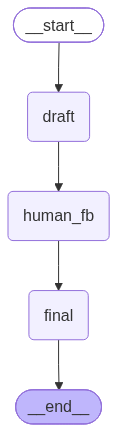

In [39]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [40]:
config={"configurable":{"thread-id":"1"}}

In [44]:
res = graph.invoke(
    {
        "query": "I want to send an email for a Medical Leave Request from 1 June to 5 June, so create a simple mail"
    },
    config=config
)

KeyError: 'thread_id'

In [ ]:
res=graph.invoke(Command(resume="I don't want to send this email!"),config=config)

In [ ]:
res